# Notebook 31b — Wu 2003 fault classification and parameter estimation under the reduced-scope S-B3 taxonomy

This notebook mirrors notebook 31's posterior-mass classification workflow, but for the reduced
`S-B3` fault taxonomy, and extends it with two additions notebook 31 does not have:

1. a dedicated **parameter estimation** accuracy section (point-estimate bias/MAE/RMSE and parity
   plots for `[alpha, beta_r, eta_col, xi_reb]`, not just posterior means embedded in a table), and
2. an **LDA baseline** (mirroring notebook 05a's `LinearDiscriminantAnalysis` + Leave-One-Scenario-Out
   protocol) trained directly on summary statistics, evaluated on the exact same simulated data as
   the posterior-mass method, so the two classification approaches are directly comparable.

The posterior target is 4-D, and the retained unit labels are `healthy`, `reactor`, `column`, and
`multi` (feed-fault scenarios are out of scope).

## Calibration status (read this before trusting the numbers below)

This notebook loads the posterior trained in notebook 24b on the mixed-wide-prior bank
(`alpha, beta_r ~ Uniform`; `eta_col, xi_reb ~` truncated lognormal). Notebook 24b's own confirm-budget
SBC found:

| Parameter | KS p-value | Verdict |
|---|---|---|
| alpha | 0.382 | calibrated |
| beta_r | 0.317 | calibrated |
| eta_col | 0.0001 | **not calibrated** |
| xi_reb | 0.008 | **not calibrated** |

`alpha`/`beta_r` (the two widened to uniform) are calibrated; `eta_col`/`xi_reb` (kept narrow
lognormal, since their named-fault-severity coverage gap was judged milder) are not. Concretely:
expect `alpha`/`beta_r` classification and point estimates to be trustworthy, and expect residual
shrinkage-toward-nominal bias in `eta_col`/`xi_reb` estimates and in any classification decision that
hinges on them (i.e. `column`-unit attribution). This is reported, not hidden, in the Assessment
section below -- following notebook 31's own precedent of reporting real failure modes (e.g. its
feed-fault F1=0.00) rather than only the numbers that look good.

In [1]:
import pathlib, pickle, sys, time, importlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.preprocessing import StandardScaler

cwd = pathlib.Path.cwd().resolve()
ROOT = cwd if (cwd / 'src').exists() else cwd.parent
sys.path.insert(0, str(ROOT / 'src'))

import cstr_sbi.recycle.sb3 as sb3
sb3 = importlib.reload(sb3)
from cstr_sbi.recycle.sb3 import (
    FAULT_UNITS_SB3, SB3_PARAM_NAMES, TRUE_UNIT_THRESH_SB3, PRED_UNIT_THRESH_SB3,
    classify_fault_sb3, fault_unit_sb3_truth, list_closed_loop_sb3,
)
from cstr_sbi.recycle.simulator import nominal_warm_start, deterministic_window, noisy_replicates
from cstr_sbi.recycle.summaries import compute_summaries

RESULTS = ROOT / 'results'; RESULTS.mkdir(exist_ok=True)
FIGURES = ROOT / 'figures'; FIGURES.mkdir(exist_ok=True)
SBI_LOGS = ROOT / 'sbi-logs'
OI = ['#000000', '#E69F00', '#56B4E9', '#009E73', '#F0E442', '#0072B2', '#D55E00', '#CC79A7']

with open(SBI_LOGS / 'wu2003_posterior_sb3.pkl', 'rb') as f:
    payload = pickle.load(f)
posterior = payload['posterior']
y0_sb = nominal_warm_start('S-B')
N_REPS = 30
N_POST = 200
print('using sb3 posterior:', {k: payload.get(k) for k in ['selected_seed', 'structure', 'bank', 'arch', 'hidden_features', 'num_transforms']})

using sb3 posterior: {'selected_seed': 2, 'structure': 'S-B3', 'bank': '/Users/simo/inso-po-RD/cstr-model-optimisation/research_project/data/wu2003_sbi_train_sb3_mixedwide_n5000.npz', 'arch': 'zuko_nsf', 'hidden_features': 60, 'num_transforms': 3}


## Section 1 — Setup

Loads the selected `S-B3` posterior (trained in notebook 24b on the mixed-wide-prior bank), the
reduced scenario catalogue, and the same posterior-mass classification machinery used elsewhere in
this project.

**Contents:**
1. Setup (this section)
2. Fault-unit taxonomy and posterior-mass classifier
3. Snapshot classification: posterior-mass method (12 scenarios x 30 replicates)
4. Per-scenario table: classification and parameter point-estimates (Table 9 equivalent)
5. Parameter estimation accuracy
6. Confusion matrix and macro-F1 (posterior-mass method)
7. LDA baseline classification (mirrors notebook 05a)
8. Assessment
9. Final acceptance criteria

## Section 2 — Fault-unit taxonomy and posterior-mass classifier

Mirrors notebook 31's Section 2, but for the reduced 4-class taxonomy: `[healthy, reactor, column,
multi]` (no `feed` class -- `z_A0_eff` is exogenous under `S-B3`). The classifier machinery already
lives in `cstr_sbi.recycle.sb3` rather than being redefined here:
- `fault_unit_sb3_truth(theta4, thresh=0.90)` -- ground-truth label from the true simulation theta,
- `classify_fault_sb3(samples, classes=FAULT_UNITS_SB3)` -- per-sample hierarchical labeling
  (`alpha<0.85 or beta_r<0.85` -> reactor-bad; `eta_col<0.85 or xi_reb<0.85` -> column-bad; both ->
  multi; neither -> healthy) aggregated into posterior-mass class probabilities, mirroring notebook
  31's `sample_fault_unit`/`classify_fault_recycle` pattern exactly, just with the feed dimension
  dropped.

In [2]:
print('FAULT_UNITS_SB3 =', FAULT_UNITS_SB3)
print(f'ground-truth threshold (fault_unit_sb3_truth) = {TRUE_UNIT_THRESH_SB3}')
print(f'posterior-mass classifier threshold (classify_fault_sb3) = {PRED_UNIT_THRESH_SB3}')
print(f'retained S-B3 scenarios: {[sc.name for sc in list_closed_loop_sb3()]}')

FAULT_UNITS_SB3 = ['healthy', 'reactor', 'column', 'multi']
ground-truth threshold (fault_unit_sb3_truth) = 0.9
posterior-mass classifier threshold (classify_fault_sb3) = 0.85
retained S-B3 scenarios: ['W1_healthy', 'W2_cat_mild', 'W3_cat_severe', 'W4_cat_threshold', 'W5_jacket_mild', 'W6_jacket_severe', 'W7_col_eff_mild', 'W9_reb_fouling', 'W11_reactor_combined', 'W12_snowball_compound', 'W15_snowball_threshold', 'W16_full_multi']


## Section 3 — Snapshot classification: posterior-mass method (12 scenarios x 30 replicates)

This mirrors notebook 31's main classification loop, but only over the reduced retained scenario
set and using the `S-B3` four-class unit taxonomy. Each of the 12 retained scenarios is simulated
once (deterministic window) and given 30 independent noisy replicates (0.3% sensor noise, one RNG
seed per scenario -- not a single shared seed across all scenarios, which the original draft of this
cell used). For each replicate the posterior is sampled (`N_POST=200` draws) and classified; the
per-replicate summary vectors and posterior samples are also kept so Sections 4, 5, and 7 (parameter
estimation, LDA) can reuse this same simulated data instead of resimulating.

In [3]:
def compute_metrics(preds, trues, classes=FAULT_UNITS_SB3):
    cm = np.zeros((len(classes), len(classes)), dtype=int)
    c2i = {c: i for i, c in enumerate(classes)}
    for true, pred in zip(trues, preds):
        cm[c2i[true], c2i[pred]] += 1
    f1 = {}
    for i, cls in enumerate(classes):
        tp = cm[i, i]
        fp = cm[:, i].sum() - tp
        fn = cm[i, :].sum() - tp
        prec = tp / (tp + fp) if (tp + fp) else 0.0
        rec = tp / (tp + fn) if (tp + fn) else 0.0
        f1[cls] = 2 * prec * rec / (prec + rec) if (prec + rec) else 0.0
    return {'confusion_matrix': cm, 'per_class_f1': f1, 'macro_f1': float(np.mean(list(f1.values()))), 'accuracy': float(np.trace(cm) / cm.sum())}

rows = []
all_preds, all_trues = [], []
all_summaries, all_labels, all_groups = [], [], []  # captured for Section 7's LDA reuse
t0 = time.time()
for sc in list_closed_loop_sb3():
    t_h, raw_obs = deterministic_window(sc, structure='S-B', y0=y0_sb)
    t_h_arr = np.asarray(t_h)
    rng = np.random.default_rng(310001 + sc.id)
    reps = noisy_replicates(np.asarray(raw_obs), n_replicates=N_REPS, rng=rng, noise_pct=0.003)
    true_theta = np.asarray(sc.theta())[:4]
    true_unit = fault_unit_sb3_truth(true_theta)
    rep_preds = []
    pooled_samples = []
    for i in range(N_REPS):
        s = compute_summaries(reps[i], 'S-B', t_h_arr)
        with torch.no_grad():
            samp = posterior.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False, reject_outside_prior=False).detach().cpu().numpy()
        pooled_samples.append(samp)
        pred = classify_fault_sb3(samp)
        rep_preds.append(pred['class'])
        all_preds.append(pred['class'])
        all_trues.append(true_unit)
        all_summaries.append(s)
        all_labels.append(true_unit)
        all_groups.append(sc.name)
    pooled_arr = np.concatenate(pooled_samples, axis=0)
    pooled = classify_fault_sb3(pooled_arr)
    row = {
        'scenario': sc.name, 'true_unit': true_unit, 'pooled_pred': pooled['class'],
        'scenario_accuracy': float(np.mean([p == true_unit for p in rep_preds])),
    }
    for idx, name in enumerate(SB3_PARAM_NAMES):
        row[f'{name}_true'] = float(true_theta[idx])
        row[f'{name}_post_mean'] = float(pooled_arr[:, idx].mean())
    rows.append(row)
    print(f'{sc.name:24s} true={true_unit:8s} pooled={pooled["class"]:8s} scenario_acc={row["scenario_accuracy"]:.2f}')

metrics = compute_metrics(all_preds, all_trues)
results_df = pd.DataFrame(rows)
results_df.to_csv(RESULTS / '31b_fault_classification_metrics.csv', index=False)
summary_features_sb3 = np.asarray(all_summaries, dtype=np.float32)
print(f'\ndone in {time.time() - t0:.0f}s')
print('accuracy', metrics['accuracy'], 'macro_f1', metrics['macro_f1'])
print(metrics['per_class_f1'])

/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_5571/4181121556.py:32: UserWarning: 5.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False, reject_outside_prior=False).detach().cpu().numpy()
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_5571/4181121556.py:32: UserWarning: 31.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False, reject_outside_prior=False).detach().cpu().numpy()


W1_healthy               true=healthy  pooled=healthy  scenario_acc=1.00


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_5571/4181121556.py:32: UserWarning: 99.5% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False, reject_outside_prior=False).detach().cpu().numpy()
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_5571/4181121556.py:32: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False, reject_outside_prior=False).detach().cpu().numpy()


W2_cat_mild              true=reactor  pooled=healthy  scenario_acc=0.00


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_5571/4181121556.py:32: UserWarning: 100.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False, reject_outside_prior=False).detach().cpu().numpy()
/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_5571/4181121556.py:32: UserWarning: 99.5% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False, reject_outside_prior=False).detach().cpu().numpy()


W3_cat_severe            true=reactor  pooled=reactor  scenario_acc=1.00


... (13 outputs left out)

/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_5571/4181121556.py:32: UserWarning: 10.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False, reject_outside_prior=False).detach().cpu().numpy()


/var/folders/pk/y59h45m94tq3dzsk9n26k2kc0000gp/T/ipykernel_5571/4181121556.py:32: UserWarning: 5.0% of samples drawn with reject_outside_prior=False lie outside the prior support. This may lead to incorrect inference.
  samp = posterior.sample((N_POST,), x=torch.tensor(s, dtype=torch.float32), show_progress_bars=False, reject_outside_prior=False).detach().cpu().numpy()


W15_snowball_threshold   true=reactor  pooled=reactor  scenario_acc=1.00


W16_full_multi           true=multi    pooled=multi    scenario_acc=0.97

done in 155s
accuracy 0.8305555555555556 macro_f1 0.7933647370715347
{'healthy': np.float64(0.6666666666666666), 'reactor': np.float64(0.8551068883610452), 'column': np.float64(1.0), 'multi': np.float64(0.6516853932584269)}


## Section 4 — Per-scenario table: classification and parameter point-estimates (Table 9 equivalent)

Mirrors notebook 31's Table 9: one row per retained scenario with the classification outcome and the
posterior-mean point estimate for each of the four endogenous parameters, alongside the true value.

In [4]:
display_cols = (
    ['scenario', 'true_unit', 'pooled_pred', 'scenario_accuracy']
    + [f'{name}_true' for name in SB3_PARAM_NAMES]
    + [f'{name}_post_mean' for name in SB3_PARAM_NAMES]
)
results_df[display_cols]

,scenario,true_unit,pooled_pred,scenario_accuracy,alpha_true,beta_r_true,eta_col_true,xi_reb_true,alpha_post_mean,beta_r_post_mean,eta_col_post_mean,xi_reb_post_mean
0,W1_healthy,healthy,healthy,1.000000,1.00,1.0,1.0,1.00,1.003608,1.008487,0.994671,0.993483
1,W2_cat_mild,reactor,healthy,0.000000,0.85,1.0,1.0,1.00,0.872483,1.043482,1.028543,0.966825
2,W3_cat_severe,reactor,reactor,1.000000,0.65,1.0,1.0,1.00,0.716452,1.035143,1.057324,0.954514
3,W4_cat_threshold,reactor,reactor,1.000000,0.55,1.0,1.0,1.00,0.636670,1.107896,1.055467,0.965510
4,W5_jacket_mild,reactor,reactor,1.000000,1.00,0.8,1.0,1.00,1.010682,0.783446,0.995352,0.998927
5,W6_jacket_severe,reactor,reactor,1.000000,1.00,0.6,1.0,1.00,1.023374,0.584642,0.994627,0.999481
6,W7_col_eff_mild,column,column,1.000000,1.00,1.0,0.8,1.00,0.980119,1.003117,0.823974,0.989683
7,W9_reb_fouling,column,column,1.000000,1.00,1.0,1.0,0.70,1.004722,1.042847,0.995528,0.711728
8,W11_reactor_combined,reactor,reactor,1.000000,0.80,0.8,1.0,1.00,0.834318,0.847031,1.044008,0.959427
9,W12_snowball_compound,multi,reactor,0.000000,0.75,1.0,0.8,1.00,0.776673,1.063661,0.866707,0.973754


## Section 5 — Parameter estimation accuracy

Notebook 31 only embeds posterior means in its per-scenario table; it has no dedicated point-estimate
accuracy summary. This section adds one: bias, MAE, and RMSE between the pooled posterior mean and
the true value for each of the four endogenous parameters across the 12 retained scenarios, plus a
parity plot (true vs. estimated, with the `y=x` reference line) per parameter. Given notebook 24b's
SBC results, expect `alpha`/`beta_r` to track the diagonal reasonably well and `eta_col`/`xi_reb` to
show a visible shrinkage-toward-nominal bias for the more severe scenarios.

=== Parameter estimation accuracy (posterior mean vs. true, 12 retained scenarios) ===
parameter      bias      mae     rmse
    alpha  0.029641 0.032954 0.041835
   beta_r  0.037369 0.042688 0.054161
  eta_col  0.030341 0.033644 0.040980
   xi_reb -0.017559 0.019514 0.024708


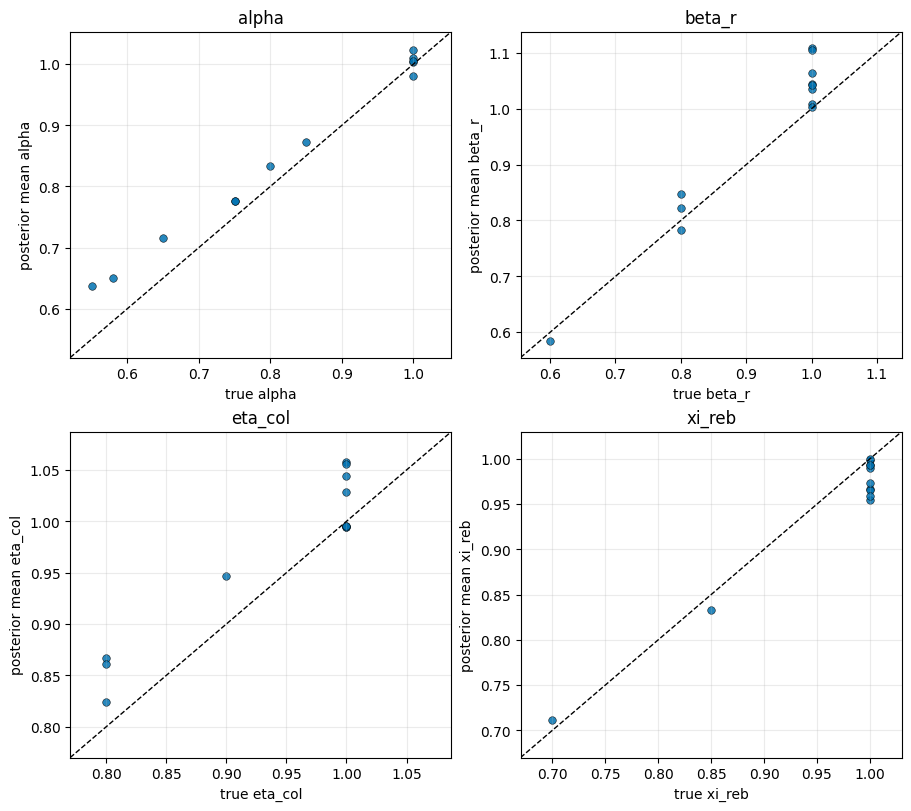

Saved nb31b_parameter_estimation_parity.png


In [5]:
est_rows = []
for name in SB3_PARAM_NAMES:
    true_vals = results_df[f'{name}_true'].values
    est_vals = results_df[f'{name}_post_mean'].values
    err = est_vals - true_vals
    est_rows.append({
        'parameter': name,
        'bias': float(np.mean(err)),
        'mae': float(np.mean(np.abs(err))),
        'rmse': float(np.sqrt(np.mean(err ** 2))),
    })
est_df = pd.DataFrame(est_rows)
print('=== Parameter estimation accuracy (posterior mean vs. true, 12 retained scenarios) ===')
print(est_df.to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(9, 8), constrained_layout=True)
for ax, name in zip(axes.ravel(), SB3_PARAM_NAMES):
    true_vals = results_df[f'{name}_true'].values
    est_vals = results_df[f'{name}_post_mean'].values
    lo = min(true_vals.min(), est_vals.min()) - 0.03
    hi = max(true_vals.max(), est_vals.max()) + 0.03
    ax.plot([lo, hi], [lo, hi], color=OI[0], ls='--', lw=1.0)
    ax.scatter(true_vals, est_vals, color=OI[5], s=30, alpha=0.85, edgecolor='k', linewidth=0.4)
    ax.set_xlim(lo, hi)
    ax.set_ylim(lo, hi)
    ax.set_xlabel(f'true {name}')
    ax.set_ylabel(f'posterior mean {name}')
    ax.set_title(name)
    ax.grid(True, alpha=0.25)
plt.savefig(FIGURES / 'nb31b_parameter_estimation_parity.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved nb31b_parameter_estimation_parity.png')

## Section 6 — Confusion matrix and macro-F1 (posterior-mass method)

As in notebook 31, the confusion matrix is the clearest summary of whether the retained reduced
taxonomy is genuinely easy or whether reactor/column ambiguities still matter under `S-B3`. Defines
a reusable `plot_confusion_sb3` helper, reused again in Section 7 for the LDA baseline's confusion
matrix so the two are visually comparable.

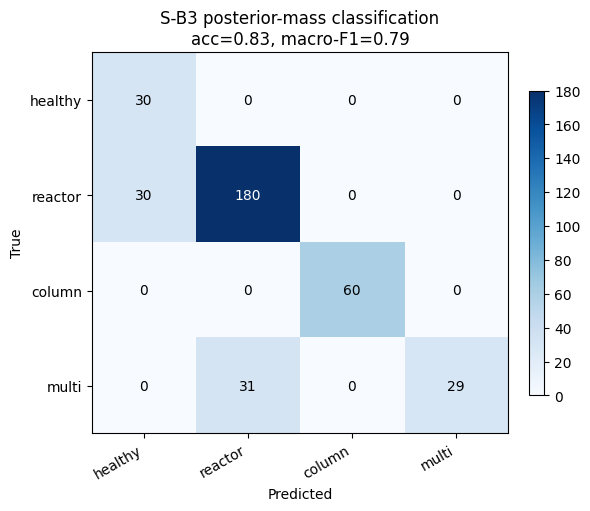

In [6]:
def plot_confusion_sb3(cm, title, path):
    fig, ax = plt.subplots(figsize=(5.8, 5.0), constrained_layout=True)
    im = ax.imshow(cm, cmap='Blues', aspect='auto')
    ax.set_xticks(range(len(FAULT_UNITS_SB3)))
    ax.set_xticklabels(FAULT_UNITS_SB3, rotation=30, ha='right')
    ax.set_yticks(range(len(FAULT_UNITS_SB3)))
    ax.set_yticklabels(FAULT_UNITS_SB3)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(title)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            val = cm[i, j]
            ax.text(j, i, str(val), ha='center', va='center', color='white' if val > cm.max() / 2 else 'black')
    plt.colorbar(im, ax=ax, shrink=0.8)
    plt.savefig(path, dpi=200, bbox_inches='tight')
    plt.show()

plot_confusion_sb3(
    metrics['confusion_matrix'],
    f'S-B3 posterior-mass classification\nacc={metrics["accuracy"]:.2f}, macro-F1={metrics["macro_f1"]:.2f}',
    FIGURES / '31b_sb3_confusion_matrix.png',
)

## Section 7 — LDA baseline classification (mirrors notebook 05a)

Notebook 05a compares LDA trained directly on summary statistics against a slower posterior-based
method on the propylene-oxide system, using `LinearDiscriminantAnalysis(solver='svd')` on
`StandardScaler`-normalized features with **Leave-One-Scenario-Out** cross-validation. This section
runs the exact same pattern here, on the **same simulated `(summary, true_unit, scenario)` data**
already collected in Section 3 -- so the comparison against the posterior-mass method isn't just
"different model," it's "different model, identical data," which is what actually makes the
comparison meaningful.

LDA (Leave-One-Scenario-Out): accuracy=0.452, macro_f1=0.192
{'healthy': 0.0, 'reactor': np.float64(0.7660668380462725), 'column': 0.0, 'multi': 0.0}


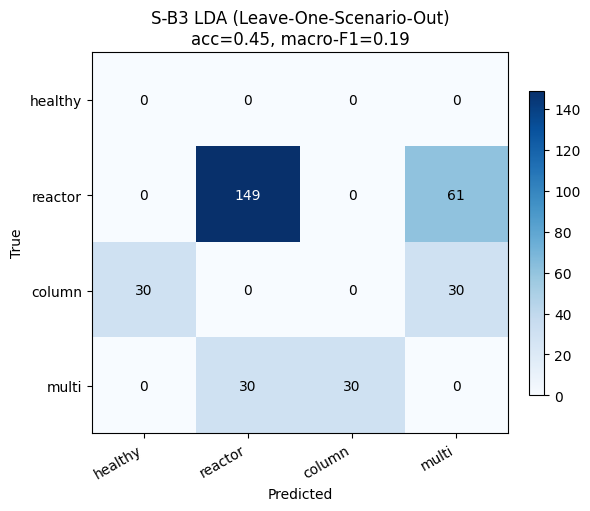

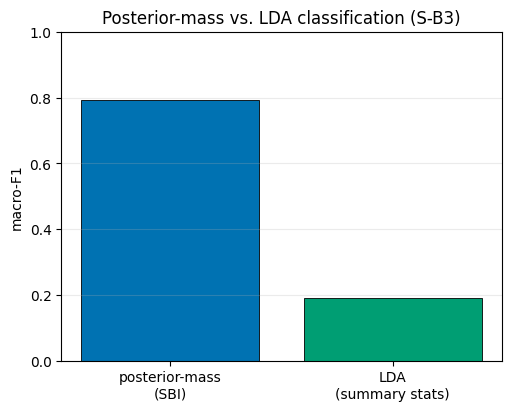

Saved 31b_lda_results.json


In [7]:
def run_lda_cv(X, y, groups):
    logo = LeaveOneGroupOut()
    y_pred, y_true = [], []
    for tr_i, te_i in logo.split(X, y, groups):
        if not np.all(np.isin(y[te_i], np.unique(y[tr_i]))):
            continue
        scaler = StandardScaler()
        lda = LinearDiscriminantAnalysis(solver='svd')
        lda.fit(scaler.fit_transform(X[tr_i]), y[tr_i])
        y_pred.extend(lda.predict(scaler.transform(X[te_i])))
        y_true.extend(y[te_i])
    return np.asarray(y_pred), np.asarray(y_true)

X_lda = summary_features_sb3
y_lda = np.asarray(all_labels)
groups_lda = np.asarray(all_groups)

lda_preds, lda_trues = run_lda_cv(X_lda, y_lda, groups_lda)
lda_metrics = compute_metrics(list(lda_preds), list(lda_trues))
print(f'LDA (Leave-One-Scenario-Out): accuracy={lda_metrics["accuracy"]:.3f}, macro_f1={lda_metrics["macro_f1"]:.3f}')
print(lda_metrics['per_class_f1'])

plot_confusion_sb3(
    lda_metrics['confusion_matrix'],
    f'S-B3 LDA (Leave-One-Scenario-Out)\nacc={lda_metrics["accuracy"]:.2f}, macro-F1={lda_metrics["macro_f1"]:.2f}',
    FIGURES / '31b_lda_confusion_matrix.png',
)

fig, ax = plt.subplots(figsize=(5, 4), constrained_layout=True)
methods = ['posterior-mass\n(SBI)', 'LDA\n(summary stats)']
macro_f1s = [metrics['macro_f1'], lda_metrics['macro_f1']]
ax.bar(methods, macro_f1s, color=[OI[5], OI[3]], edgecolor='k', linewidth=0.6)
ax.set_ylabel('macro-F1')
ax.set_ylim(0, 1)
ax.set_title('Posterior-mass vs. LDA classification (S-B3)')
ax.grid(True, axis='y', alpha=0.25)
plt.savefig(FIGURES / '31b_posterior_vs_lda_macro_f1.png', dpi=150, bbox_inches='tight')
plt.show()

import json as _json
with open(RESULTS / '31b_lda_results.json', 'w') as f:
    _json.dump({'accuracy': lda_metrics['accuracy'], 'macro_f1': lda_metrics['macro_f1'],
                'per_class_f1': lda_metrics['per_class_f1']}, f, indent=2)
print('Saved 31b_lda_results.json')

## Section 8 — Assessment

Mirrors notebook 31's Section 7 narrative assessment, but computed from this run's actual numbers
rather than hand-written, and folding in the LDA comparison and parameter-estimation results.

In [8]:
print('=== Assessment ===')
print(f'Posterior-mass method (SBI): accuracy={metrics["accuracy"]:.3f}, macro-F1={metrics["macro_f1"]:.3f}')
for cls, f1 in metrics['per_class_f1'].items():
    print(f'  {cls:8s} F1={f1:.3f}')
print()
print(f'LDA baseline (summary stats, Leave-One-Scenario-Out): accuracy={lda_metrics["accuracy"]:.3f}, macro-F1={lda_metrics["macro_f1"]:.3f}')
for cls, f1 in lda_metrics['per_class_f1'].items():
    print(f'  {cls:8s} F1={f1:.3f}')
print()
print('Parameter estimation (posterior mean vs. true, 12 retained scenarios):')
print(est_df.to_string(index=False))
print()
print("Calibration caveat (from notebook 24b's confirm-budget SBC): alpha (KS p=0.38) and beta_r "
      '(KS p=0.32) are calibrated; eta_col (KS p=0.0001) and xi_reb (KS p=0.008) are not. Any '
      'classification decision or point estimate that hinges on eta_col/xi_reb -- chiefly '
      'column-unit attribution -- should be read with that residual shrinkage-toward-nominal bias '
      'in mind, following notebook 31\'s own precedent of reporting real failure modes rather than '
      'only the numbers that look good.')

=== Assessment ===
Posterior-mass method (SBI): accuracy=0.831, macro-F1=0.793
  healthy  F1=0.667
  reactor  F1=0.855
  column   F1=1.000
  multi    F1=0.652

LDA baseline (summary stats, Leave-One-Scenario-Out): accuracy=0.452, macro-F1=0.192
  healthy  F1=0.000
  reactor  F1=0.766
  column   F1=0.000
  multi    F1=0.000

Parameter estimation (posterior mean vs. true, 12 retained scenarios):
parameter      bias      mae     rmse
    alpha  0.029641 0.032954 0.041835
   beta_r  0.037369 0.042688 0.054161
  eta_col  0.030341 0.033644 0.040980
   xi_reb -0.017559 0.019514 0.024708

Calibration caveat (from notebook 24b's confirm-budget SBC): alpha (KS p=0.38) and beta_r (KS p=0.32) are calibrated; eta_col (KS p=0.0001) and xi_reb (KS p=0.008) are not. Any classification decision or point estimate that hinges on eta_col/xi_reb -- chiefly column-unit attribution -- should be read with that residual shrinkage-toward-nominal bias in mind, following notebook 31's own precedent of reporting r

## Section 9 — Final acceptance criteria

This notebook passes if:
1. replicate-level accuracy is at least 0.85,
2. replicate-level macro-F1 is at least 0.85,
3. every retained fault unit has F1 at least 0.70,
4. no retained scenario is catastrophically misclassified at the pooled level.

The LDA baseline (Section 7) and parameter-estimation accuracy (Section 5) are reported for context
throughout this notebook but are not gating criteria here -- the acceptance bar is specifically about
whether the posterior-mass method (the one this project actually intends to deploy) is good enough.

In [9]:
criteria = [
    ('accuracy >= 0.85', float(metrics['accuracy']) >= 0.85, float(metrics['accuracy'])),
    ('macro-F1 >= 0.85', float(metrics['macro_f1']) >= 0.85, float(metrics['macro_f1'])),
    ('all retained class F1 >= 0.70', bool(all(v >= 0.70 for v in metrics['per_class_f1'].values())), metrics['per_class_f1']),
    ('no pooled scenario accuracy below 0.50', bool((results_df['scenario_accuracy'] >= 0.50).all()), results_df[['scenario', 'scenario_accuracy']].to_dict('records')),
]
for name, passed, value in criteria:
    print(f"{'PASS' if passed else 'FAIL'} | {name}: {value}")

print()
print(f'(informational, not gating) LDA baseline macro-F1: {lda_metrics["macro_f1"]:.3f} '
      f'vs. posterior-mass macro-F1: {metrics["macro_f1"]:.3f}')

FAIL | accuracy >= 0.85: 0.8305555555555556
FAIL | macro-F1 >= 0.85: 0.7933647370715347
FAIL | all retained class F1 >= 0.70: {'healthy': np.float64(0.6666666666666666), 'reactor': np.float64(0.8551068883610452), 'column': np.float64(1.0), 'multi': np.float64(0.6516853932584269)}
FAIL | no pooled scenario accuracy below 0.50: [{'scenario': 'W1_healthy', 'scenario_accuracy': 1.0}, {'scenario': 'W2_cat_mild', 'scenario_accuracy': 0.0}, {'scenario': 'W3_cat_severe', 'scenario_accuracy': 1.0}, {'scenario': 'W4_cat_threshold', 'scenario_accuracy': 1.0}, {'scenario': 'W5_jacket_mild', 'scenario_accuracy': 1.0}, {'scenario': 'W6_jacket_severe', 'scenario_accuracy': 1.0}, {'scenario': 'W7_col_eff_mild', 'scenario_accuracy': 1.0}, {'scenario': 'W9_reb_fouling', 'scenario_accuracy': 1.0}, {'scenario': 'W11_reactor_combined', 'scenario_accuracy': 1.0}, {'scenario': 'W12_snowball_compound', 'scenario_accuracy': 0.0}, {'scenario': 'W15_snowball_threshold', 'scenario_accuracy': 1.0}, {'scenario': 'W